# How AI is Shaping Developers' Work and Careers

### 1. Business Understanding 

Artificial Intelligence tools are becoming common place in assisting with software development. This project explores how AI adoption affects developers careers using responses form the Stack Overflow Developer Survey. 

1. How does AI adoption vary across different career stages?
2. Is AI usage associated with differences in developer salary?
3. How does AI usage relate to developers' views of their career future?

In addition to exploratory analysis, a machine learning classification model will be 
developed to determine whether developer characteristics can help predict AI adoption.

### 2. Data Understanding and Exploratory Data Analysis

In [1]:
#import libraries 

import pandas as pd
#import shap as sp
import numpy as np
import sklearn 
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error

In [2]:
#import the dataset

df = pd.read_csv('results.csv', low_memory=False)

The dataset is first inspected to understand its size, structure, data types, and 
available variables before making any cleaning or modeling decisions.

In [3]:
df.head()

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


In [4]:
df.shape

(49191, 172)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Columns: 172 entries, ResponseId to JobSat
dtypes: float64(52), int64(1), object(119)
memory usage: 64.6+ MB


In [6]:
df.describe()

,ResponseId,WorkExp,YearsCode,TechEndorse_1,TechEndorse_2,TechEndorse_3,TechEndorse_4,TechEndorse_5,TechEndorse_6,TechEndorse_7,...,SO_Actions_3,SO_Actions_4,SO_Actions_5,SO_Actions_6,SO_Actions_9,SO_Actions_7,SO_Actions_10,SO_Actions_15,ConvertedCompYearly,JobSat
count,49191.000000,42893.000000,43042.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,35975.000000,...,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,26260.000000,2.394700e+04,26670.000000
mean,24596.000000,13.367403,16.570861,7.867352,4.104211,4.110271,5.678193,4.119388,5.225990,6.477387,...,5.718355,4.561767,4.790861,5.199657,5.676314,4.984653,7.099505,10.079284,1.017615e+05,7.201950
std,14200.362883,10.800117,11.787610,2.397432,2.275821,2.329536,2.398084,2.437945,2.801045,2.331468,...,2.628016,3.070548,2.643177,2.563562,2.310659,2.490095,2.469394,1.940928,4.617569e+05,1.997245
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,0.000000
25%,12298.500000,5.000000,8.000000,7.000000,2.000000,2.000000,4.000000,2.000000,3.000000,5.000000,...,3.000000,1.000000,3.000000,3.000000,4.000000,3.000000,6.000000,10.000000,3.817100e+04,6.000000
50%,24596.000000,10.000000,14.000000,9.000000,4.000000,4.000000,6.000000,4.000000,5.000000,7.000000,...,6.000000,4.000000,5.000000,5.000000,6.000000,5.000000,8.000000,10.000000,7.532000e+04,8.000000
75%,36893.500000,20.000000,24.000000,9.000000,6.000000,6.000000,8.000000,6.000000,8.000000,8.000000,...,8.000000,7.000000,7.000000,7.000000,7.000000,7.000000,9.000000,10.000000,1.205960e+05,8.000000
max,49191.000000,100.000000,100.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,14.000000,...,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,5.000000e+07,10.000000


In [7]:
#getting full list of columns 
list(df.columns)

['ResponseId',
 'MainBranch',
 'Age',
 'EdLevel',
 'Employment',
 'EmploymentAddl',
 'WorkExp',
 'LearnCodeChoose',
 'LearnCode',
 'LearnCodeAI',
 'AILearnHow',
 'YearsCode',
 'DevType',
 'OrgSize',
 'ICorPM',
 'RemoteWork',
 'PurchaseInfluence',
 'TechEndorseIntro',
 'TechEndorse_1',
 'TechEndorse_2',
 'TechEndorse_3',
 'TechEndorse_4',
 'TechEndorse_5',
 'TechEndorse_6',
 'TechEndorse_7',
 'TechEndorse_8',
 'TechEndorse_9',
 'TechEndorse_13',
 'TechEndorse_13_TEXT',
 'TechOppose_1',
 'TechOppose_2',
 'TechOppose_3',
 'TechOppose_5',
 'TechOppose_7',
 'TechOppose_9',
 'TechOppose_11',
 'TechOppose_13',
 'TechOppose_16',
 'TechOppose_15',
 'TechOppose_15_TEXT',
 'Industry',
 'JobSatPoints_1',
 'JobSatPoints_2',
 'JobSatPoints_3',
 'JobSatPoints_4',
 'JobSatPoints_5',
 'JobSatPoints_6',
 'JobSatPoints_7',
 'JobSatPoints_8',
 'JobSatPoints_9',
 'JobSatPoints_10',
 'JobSatPoints_11',
 'JobSatPoints_13',
 'JobSatPoints_14',
 'JobSatPoints_15',
 'JobSatPoints_16',
 'JobSatPoints_15_TEXT',
 

In [8]:
df["WorkExp"].describe()

count    42893.000000
mean        13.367403
std         10.800117
min          1.000000
25%          5.000000
50%         10.000000
75%         20.000000
max        100.000000
Name: WorkExp, dtype: float64

In [9]:
df["WorkExp"].value_counts(dropna=False).sort_index()

WorkExp
1.0      2453
2.0      2408
3.0      2613
4.0      2166
5.0      2563
         ... 
82.0        1
88.0        1
99.0        5
100.0      34
NaN      6298
Name: count, Length: 73, dtype: int64

In [10]:
df["AISelect"].value_counts(dropna=False)

AISelect
Yes, I use AI tools daily                      15883
NaN                                            15471
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797
Name: count, dtype: int64

In [11]:
df["YearsCode"].describe()

count    43042.000000
mean        16.570861
std         11.787610
min          1.000000
25%          8.000000
50%         14.000000
75%         24.000000
max        100.000000
Name: YearsCode, dtype: float64

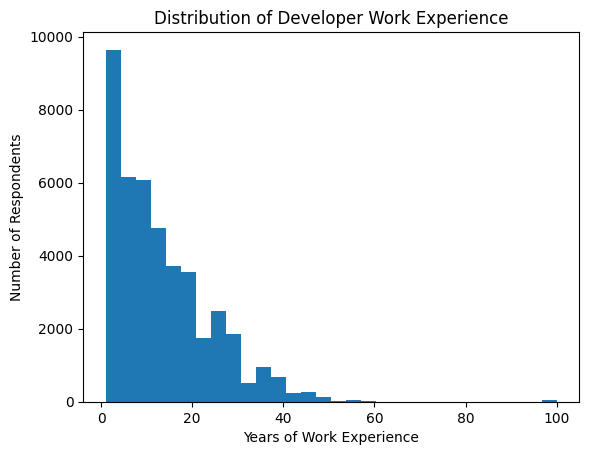

In [12]:
#Work Experience 

plt.hist(df['WorkExp'].dropna(), bins=30)
plt.xlabel('Years of Work Experience')
plt.ylabel('Number of Respondents')
plt.title('Distribution of Developer Work Experience')
plt.show()

The distribution of `WorkExp` is strongly right-skewed. Most respondents have 
approximately 1–20 years of professional work experience, while relatively few 
respondents report more than 40 years. A small number of extremely high values 
near 100 years are also present and require further investigation.

In [13]:
# Reviewing the age in regards to work experience
df.loc[
    df['WorkExp'] > 60,
    ['Age', 'WorkExp', 'YearsCode']
].sort_values('WorkExp')

,Age,WorkExp,YearsCode
10238,65 years or older,61.0,4.0
33407,65 years or older,61.0,30.0
38177,65 years or older,63.0,50.0
2520,65 years or older,65.0,65.0
23458,Prefer not to say,65.0,20.0
40501,65 years or older,65.0,60.0
48902,65 years or older,66.0,45.0
5430,65 years or older,68.0,55.0
19375,65 years or older,68.0,68.0
7940,25-34 years old,69.0,69.0


In [14]:
# Replace unrealistic WorkExp values above 60 with missing values

df.loc[df['WorkExp'] > 60, 'WorkExp'] = np.nan

In [15]:
df[df['WorkExp'] > 60]

,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat


Inspection of the extreme `WorkExp` values revealed several implausible responses. 
For example, some respondents aged 18–24 reported between 75 and 100 years of 
professional work experience. Because these values cannot reasonably represent 
professional experience, values greater than 60 were treated as invalid.

Rather than removing the respondents entirely, only the invalid `WorkExp` values 
were replaced with missing values (`NaN`) so that their responses to other survey 
questions could still be retained.

In [16]:
#Identify columns related to dev compensation

[col for col in df.columns if 'Comp' in col or 'Salary' in col or 'Pay' in col]

['CompTotal', 'AIComplex', 'ConvertedCompYearly']

In [17]:
# Review the distribution and summary statistics of annual compensation
df['ConvertedCompYearly'].describe()

count    2.394700e+04
mean     1.017615e+05
std      4.617569e+05
min      1.000000e+00
25%      3.817100e+04
50%      7.532000e+04
75%      1.205960e+05
max      5.000000e+07
Name: ConvertedCompYearly, dtype: float64

In [18]:
# Checking the number of missing annual compensation values
df['ConvertedCompYearly'].isna().sum()

np.int64(25244)

In [19]:
# Calculate the percentage of respondents missing compensation data

df['ConvertedCompYearly'].isna().mean() * 100

np.float64(51.31833058892887)

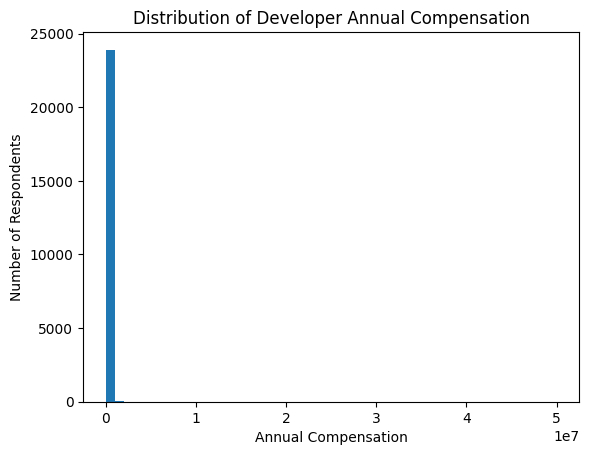

In [20]:
plt.hist(
    df['ConvertedCompYearly'].dropna(),
    bins=50
)

plt.xlabel('Annual Compensation')
plt.ylabel('Number of Respondents')
plt.title('Distribution of Developer Annual Compensation')
plt.show()

In [21]:
# Review summary statistics for annual compensation
df['ConvertedCompYearly'].describe()

count    2.394700e+04
mean     1.017615e+05
std      4.617569e+05
min      1.000000e+00
25%      3.817100e+04
50%      7.532000e+04
75%      1.205960e+05
max      5.000000e+07
Name: ConvertedCompYearly, dtype: float64

In [22]:
# Inspect the highest reported annual compensation values
df['ConvertedCompYearly'].sort_values(ascending=False).head(20)

34267    50000000.0
28700    33552715.0
43143    18387548.0
35353    15430267.0
45971    13921760.0
48428    10000000.0
24900     9531653.0
10025     9000000.0
37352     6890299.0
30728     6371285.0
40418     6000000.0
19536     5810837.0
28055     5000000.0
14873     4706124.0
48023     3900562.0
28058     3900000.0
39349     3821169.0
25268     2500000.0
5410      2346000.0
34975     2000000.0
Name: ConvertedCompYearly, dtype: float64

In [23]:
# Review upper percentiles to understand extreme compensation values
df['ConvertedCompYearly'].quantile([0.90, 0.95, 0.99, 0.995, 0.999])

0.900    1.840000e+05
0.950    2.320290e+05
0.990    4.408560e+05
0.995    6.000000e+05
0.999    1.563024e+06
Name: ConvertedCompYearly, dtype: float64

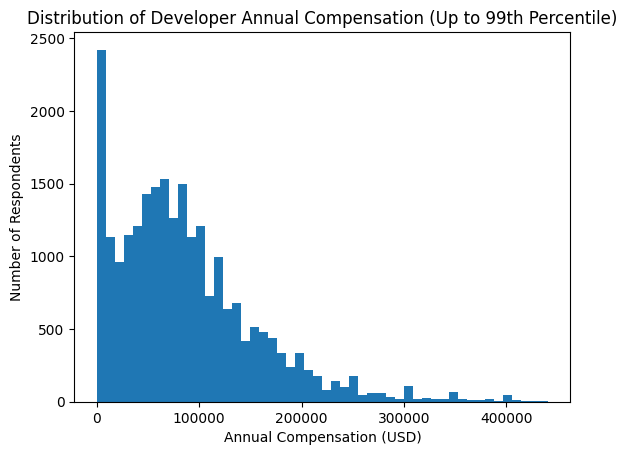

In [24]:
# Visualize compensation for the majority of respondents
salary_99 = df['ConvertedCompYearly'].quantile(0.99)

plt.hist(
    df.loc[
        df['ConvertedCompYearly'] <= salary_99,
        'ConvertedCompYearly'
    ].dropna(),
    bins=50
)

plt.xlabel('Annual Compensation (USD)')
plt.ylabel('Number of Respondents')
plt.title('Distribution of Developer Annual Compensation (Up to 99th Percentile)')
plt.show()

The annual compensation distribution is highly right-skewed. The median compensation is approximately $75,320, while the man is approximately $101,762, suggesting that high compesnation values are pulling the man upward. The maximum reported compensatino is $50 million, while 99$ of respondents report compensation below approximately $440,856. Because high compensation is possible for some senior or specialized technology roles, these values were not automatically treated as invalid. A second histogram limited to the 99th percentile was used to better visualize the compensation distribution for the majority of respondents without altering the underlying dataset.

In [25]:
#Creating a column to categorize different stages of Career
df['CareerStage'] = pd.cut(
    df['WorkExp'],
    bins=[0, 5, 10, 20, float('inf')],
    labels=[
        'Early Career',
        'Mid Career',
        'Experienced',
        'Highly Experienced'
    ]
)


In [26]:
#Creating a column to classify AI adoption 
print(df['AISelect'].value_counts(dropna=False))
print("------------------------")

def group_ai_adoption(value):
    if pd.isna(value):
        return np.nan
    elif value.startswith('Yes'):
        return 'AI User'
    else:
        return 'Non-AI User'

df['AIAdoption'] = df['AISelect'].apply(group_ai_adoption)

print(df['AIAdoption'].value_counts(dropna=False))


AISelect
Yes, I use AI tools daily                      15883
NaN                                            15471
Yes, I use AI tools weekly                      5958
No, and I don't plan to                         5454
Yes, I use AI tools monthly or infrequently     4628
No, but I plan to soon                          1797
Name: count, dtype: int64
------------------------
AIAdoption
AI User        26469
NaN            15471
Non-AI User     7251
Name: count, dtype: int64


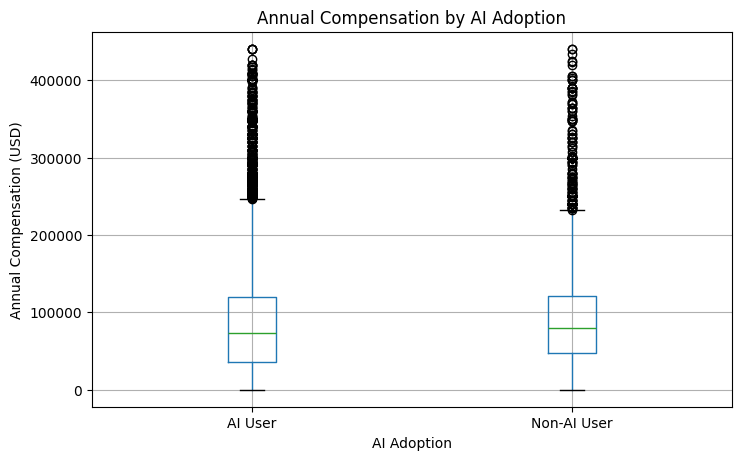

In [27]:
# Compare compensation distributions for AI users and non-AI users
salary_plot = df[
    (df['ConvertedCompYearly'] <= salary_99) &
    (df['AIAdoption'].notna())
]

salary_plot.boxplot(
    column='ConvertedCompYearly',
    by='AIAdoption',
    figsize=(8, 5)
)

plt.title('Annual Compensation by AI Adoption')
plt.suptitle('')
plt.xlabel('AI Adoption')
plt.ylabel('Annual Compensation (USD)')
plt.show()

In [28]:
# Create salary groups for current AI users and non-AI users
ai_salary = df.loc[
    df['AIAdoption'] == 'AI User',
    'ConvertedCompYearly'
].dropna()

non_ai_salary = df.loc[
    df['AIAdoption'] == 'Non-AI User',
    'ConvertedCompYearly'
].dropna()

In [29]:
# Test whether compensation distributions differ between AI users and non-AI users
from scipy.stats import mannwhitneyu

stat, p = mannwhitneyu(
    ai_salary,
    non_ai_salary,
    alternative='two-sided'
)

print("Mann-Whitney U statistic:", stat)
print("p-value:", p)

Mann-Whitney U statistic: 39428827.0
p-value: 3.2654291429089063e-10


In [30]:
# Interpret statistical significance using a 5% significance level
alpha = 0.05

if p < alpha:
    print("There is a statistically significant difference in compensation between AI users and non-AI users.")
else:
    print("There is not enough evidence to conclude that compensation differs between AI users and non-AI users.")

There is a statistically significant difference in compensation between AI users and non-AI users.


The Mann–Whitney U test produced a p-value well below the 0.05 significance level, indicating a statistically significant difference in annual compensation between AI users and non-AI users.

However, statistical significance does not necessarily mean that the difference is large or practically important. The median compensation difference between the two groups is relatively modest, so additional analysis is needed to determine whether other factors, such as career stage, may help explain the difference.

In [31]:
# Compare median annual compensation by career stage and AI adoption
salary_by_stage_ai = df.groupby(
    ['CareerStage', 'AIAdoption'],
    observed=True
)['ConvertedCompYearly'].median().unstack()

salary_by_stage_ai

AIAdoption,AI User,Non-AI User
CareerStage,,
Early Career,34804.0,48726.0
Mid Career,71899.0,76876.0
Experienced,93326.0,90000.0
Highly Experienced,113451.5,99773.0


In [32]:
# Round median compensation values for easier interpretation
salary_by_stage_ai.round(2)

AIAdoption,AI User,Non-AI User
CareerStage,,
Early Career,34804.0,48726.0
Mid Career,71899.0,76876.0
Experienced,93326.0,90000.0
Highly Experienced,113451.5,99773.0


In [33]:
# Compare median annual compensation by career stage and AI adoption
salary_by_stage_ai = df.groupby(
    ['CareerStage', 'AIAdoption'],
    observed=True
)['ConvertedCompYearly'].median().unstack()

salary_by_stage_ai.round(2)

AIAdoption,AI User,Non-AI User
CareerStage,,
Early Career,34804.0,48726.0
Mid Career,71899.0,76876.0
Experienced,93326.0,90000.0
Highly Experienced,113451.5,99773.0


Overall, non-AI users had a slightly higher median annual compensation than AI users. However, the relationship changed when compensation was examined within career stages.

Among early- and mid-career respondents, non-AI users had higher median compensation. In contrast, among experienced and highly experienced respondents, AI users had higher median compensation.

This suggests that career stage may influence the relationship between AI usage and salary, and that AI adoption alone does not explain differences in compensation.

In [34]:
# Review developers' responses about whether AI threatens their current job
df['AIThreat'].value_counts(dropna=False)

AIThreat
No              22958
NaN             13113
I'm not sure     7700
Yes              5420
Name: count, dtype: int64

In [35]:
# Review job satisfaction responses
df['JobSat'].value_counts(dropna=False)

JobSat
NaN     22521
8.0      6972
7.0      5590
9.0      3598
6.0      3230
10.0     2924
5.0      1896
3.0       811
4.0       803
2.0       439
0.0       242
1.0       165
Name: count, dtype: int64

In [36]:
# Compare perceptions of AI job threat by AI adoption
threat_by_ai = pd.crosstab(
    df['AIAdoption'],
    df['AIThreat'],
    normalize='index'
) * 100

threat_by_ai.round(1)

AIThreat,I'm not sure,No,Yes
AIAdoption,,,
AI User,21.9,62.9,15.2
Non-AI User,18.9,69.9,11.2


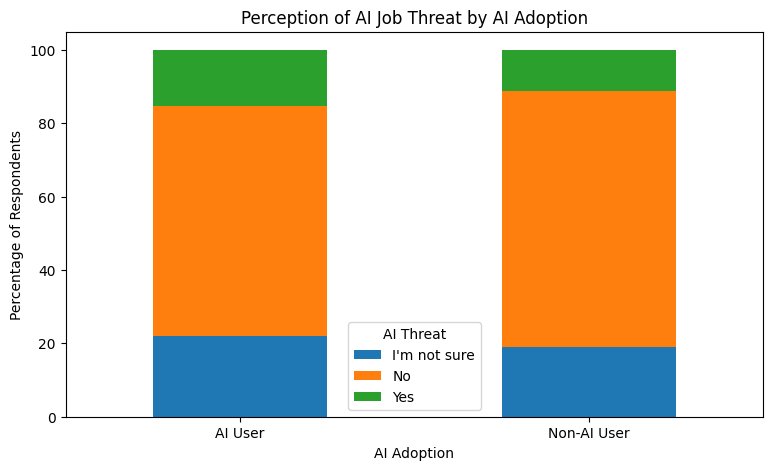

In [37]:
# Visualize perceptions of AI job threat by AI adoption
threat_by_ai.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Perception of AI Job Threat by AI Adoption')
plt.xlabel('AI Adoption')
plt.ylabel('Percentage of Respondents')
plt.xticks(rotation=0)
plt.legend(title='AI Threat')
plt.show()

AI users were somewhat more likely to view AI as a threat to their current job. 
About 15.2% of AI users reported that AI threatens their job, compared with 11.2% 
of non-AI users.

AI users were also slightly more likely to be unsure about the threat, while 
non-AI users were more likely to say that AI was not a threat.

Overall, most respondents in both groups did not view AI as a threat to their 
current job, but concern was somewhat higher among current AI users.

### 3 Data preparation 

Career stages were defined as:

- **Early Career:** 1–5 years
- **Mid Career:** 6–10 years
- **Experienced:** 11–20 years
- **Highly Experienced:** more than 20 years

In [39]:
df['CareerStage'].value_counts(dropna=False)

CareerStage
Early Career          12203
Experienced           12026
Mid Career             9654
Highly Experienced     8956
NaN                    6352
Name: count, dtype: int64

`AISelect` contains several responses describing how frequently respondents use AI 
tools. For this analysis, respondents who reported using AI daily, weekly, monthly, 
or infrequently were classified as **AI Users**.

Respondents who reported that they do not currently use AI were classified as 
**Non-AI Users**, including those who stated that they plan to use AI in the future. 
Missing responses were retained as missing values.

In [40]:
ai_by_career = pd.crosstab(
    df['CareerStage'],
    df['AIAdoption'],
    normalize='index'
) * 100

ai_by_career

AIAdoption,AI User,Non-AI User
CareerStage,,
Early Career,83.067729,16.932271
Mid Career,81.922463,18.077537
Experienced,79.187987,20.812013
Highly Experienced,71.364965,28.635035


### 
AI adoption declines as professional work experience increases. Approximately 83.1% 
of early-career respondents reported currently using AI tools, compared with 81.9% 
of mid-career respondents, 79.2% of experienced respondents, and 71.4% of highly 
experienced respondents.

The pattern suggests that developers earlier in their professional careers are more 
likely to report using AI tools than developers with longer professional experience. 

# graph here. 

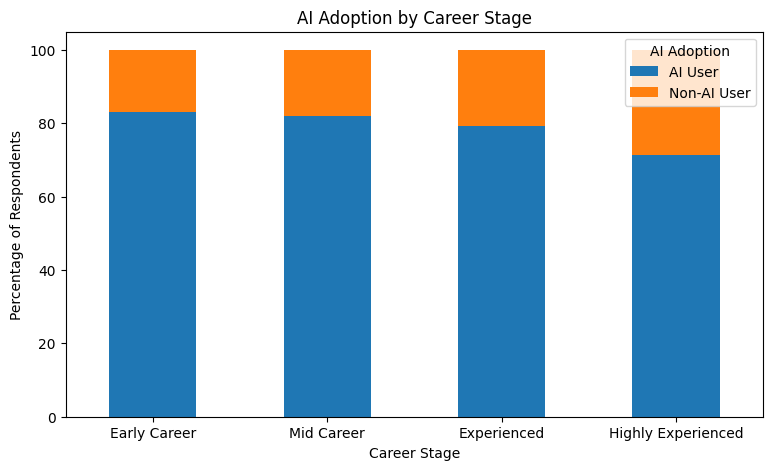

In [41]:
ai_by_career.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('AI Adoption by Career Stage')
plt.xlabel('Career Stage')
plt.ylabel('Percentage of Respondents')
plt.xticks(rotation=0)
plt.legend(title='AI Adoption')
plt.show()

In [42]:
from scipy.stats import chi2_contingency

In [43]:
contingency_table = pd.crosstab(
    df['CareerStage'],
    df['AIAdoption']
)

contingency_table

AIAdoption,AI User,Non-AI User
CareerStage,,
Early Career,6672,1360
Mid Career,5642,1245
Experienced,7119,1871
Highly Experienced,5129,2058


In [44]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(contingency_table)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 368.13013620732886
p-value: 1.768773894448763e-79
Degrees of freedom: 3


In [45]:
alpha = 0.05

if p < alpha:
    print("There is a statistically significant relationship between career stage and AI adoption.")
else:
    print("There is not enough evidence to conclude that career stage and AI adoption are related.")

There is a statistically significant relationship between career stage and AI adoption.


In [46]:
n = contingency_table.to_numpy().sum()
min_dim = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramer's V:", cramers_v)

Cramer's V: 0.1088048919343894


The chi-square test was used to determine whether career stage and AI adoption were 
independent. The resulting p-value was below the 0.05 significance threshold, providing 
evidence of an association between career stage and AI adoption.

However, statistical significance does not necessarily imply a strong relationship. 
Cramér's V was therefore calculated to measure the strength of the association. The 
result indicates that the relationship between career stage and AI adoption is relatively 
weak, even though the difference is statistically significant.

# 4. Analyst of Research Questions




###  4.1 AI Adoption and Career Stage

In [59]:
candidate_features = [
    'YearsCode',
    'DevType',
    'ConvertedCompYearly',
    'EdLevel',
    'Employment',
    'RemoteWork',
    'Country'
]

[col for col in candidate_features if col in df.columns]

['YearsCode',
 'DevType',
 'ConvertedCompYearly',
 'EdLevel',
 'Employment',
 'RemoteWork',
 'Country']

In [60]:
[col for col in candidate_features if col not in df.columns]

[]

In [61]:
model_df = df[
    candidate_features + ['AIAdoption']
].copy()

model_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YearsCode            43042 non-null  float64
 1   DevType              43680 non-null  object 
 2   ConvertedCompYearly  23947 non-null  float64
 3   EdLevel              48149 non-null  object 
 4   Employment           48339 non-null  object 
 5   RemoteWork           33780 non-null  object 
 6   Country              35437 non-null  object 
 7   AIAdoption           33720 non-null  object 
dtypes: float64(2), object(6)
memory usage: 3.0+ MB


In [62]:
model_df.isna().sum()

YearsCode               6149
DevType                 5511
ConvertedCompYearly    25244
EdLevel                 1042
Employment               852
RemoteWork             15411
Country                13754
AIAdoption             15471
dtype: int64

In [63]:
(model_df.isna().mean() * 100).round(1)

YearsCode              12.5
DevType                11.2
ConvertedCompYearly    51.3
EdLevel                 2.1
Employment              1.7
RemoteWork             31.3
Country                28.0
AIAdoption             31.5
dtype: float64

In [64]:
model_df = model_df.dropna(subset=['AIAdoption'])

model_df.shape

(33720, 8)

In [65]:
(model_df.isna().mean() * 100).round(1)

YearsCode               1.3
DevType                 0.0
ConvertedCompYearly    31.2
EdLevel                 0.2
Employment              0.0
RemoteWork             21.2
Country                 0.0
AIAdoption              0.0
dtype: float64

In [66]:
model_df['AIAdoption'].value_counts()

AIAdoption
AI User        26469
Non-AI User     7251
Name: count, dtype: int64

In [67]:
(model_df['AIAdoption'].value_counts(normalize=True) * 100).round(1)

AIAdoption
AI User        78.5
Non-AI User    21.5
Name: proportion, dtype: float64

In [68]:
model_df[
    ['DevType', 'EdLevel', 'Employment', 'RemoteWork', 'Country']
].nunique()

DevType        32
EdLevel         8
Employment      6
RemoteWork      5
Country       176
dtype: int64

In [69]:
X = model_df[candidate_features]
y = model_df['AIAdoption']

In [70]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 26976
Testing rows: 6744


In [72]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummy_model = DummyClassifier(strategy='most_frequent')

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

dummy_accuracy = accuracy_score(y_test, dummy_predictions)

print("Baseline Accuracy:", round(dummy_accuracy, 3))

Baseline Accuracy: 0.785


In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [74]:
numeric_features = [
    'YearsCode',
    'ConvertedCompYearly'
]

categorical_features = [
    'DevType',
    'EdLevel',
    'Employment',
    'RemoteWork',
    'Country'
]

In [75]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', StandardScaler())
])

In [76]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('onehot', OneHotEncoder(
        handle_unknown='ignore'
    ))
])

In [77]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [78]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [79]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['YearsCode',
                                                   'ConvertedCompYearly']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['DevType', 'EdLevel',
                                                   'Employment', 'RemoteWork',
                                                   'Country'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [80]:
y_pred = logistic_model.predict(X_test)

In [81]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(
    accuracy_score(y_test, y_pred),
    3
))

print()

print(classification_report(
    y_test,
    y_pred
))

Accuracy: 0.642

              precision    recall  f1-score   support

     AI User       0.86      0.65      0.74      5294
 Non-AI User       0.33      0.62      0.43      1450

    accuracy                           0.64      6744
   macro avg       0.59      0.64      0.58      6744
weighted avg       0.75      0.64      0.67      6744



In [82]:
from sklearn.metrics import balanced_accuracy_score

balanced_acc = balanced_accuracy_score(
    y_test,
    y_pred
)

print("Balanced Accuracy:", round(balanced_acc, 3))

Balanced Accuracy: 0.635


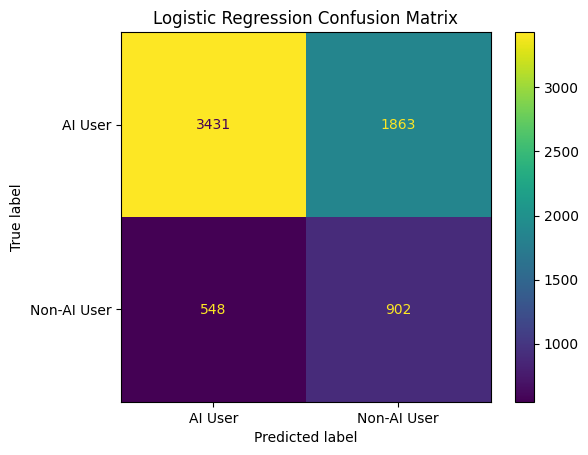

In [83]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['AI User', 'Non-AI User']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['AI User', 'Non-AI User']
)

disp.plot()
plt.title('Logistic Regression Confusion Matrix')
plt.show()

In [84]:
logistic_model.classes_

array(['AI User', 'Non-AI User'], dtype=object)

In [85]:
from sklearn.metrics import roc_auc_score

ai_user_index = list(logistic_model.classes_).index('AI User')

y_prob = logistic_model.predict_proba(X_test)[:, ai_user_index]

y_test_binary = (y_test == 'AI User').astype(int)

roc_auc = roc_auc_score(
    y_test_binary,
    y_prob
)

print("ROC-AUC:", round(roc_auc, 3))

ROC-AUC: 0.689


In [86]:
regular_logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

regular_logistic_model.fit(X_train, y_train)

regular_pred = regular_logistic_model.predict(X_test)

In [87]:
print(
    "Accuracy:",
    round(accuracy_score(y_test, regular_pred), 3)
)

print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(y_test, regular_pred),
        3
    )
)

print()

print(
    classification_report(
        y_test,
        regular_pred
    )
)

Accuracy: 0.787
Balanced Accuracy: 0.528

              precision    recall  f1-score   support

     AI User       0.79      0.98      0.88      5294
 Non-AI User       0.54      0.07      0.13      1450

    accuracy                           0.79      6744
   macro avg       0.67      0.53      0.50      6744
weighted avg       0.74      0.79      0.72      6744



In [88]:
ai_user_index = list(
    regular_logistic_model.classes_
).index('AI User')

regular_prob = regular_logistic_model.predict_proba(
    X_test
)[:, ai_user_index]

regular_auc = roc_auc_score(
    y_test_binary,
    regular_prob
)

print("ROC-AUC:", round(regular_auc, 3))

ROC-AUC: 0.69


In [89]:
model_comparison = pd.DataFrame({
    'Model': [
        'Dummy Baseline',
        'Regular Logistic Regression',
        'Balanced Logistic Regression'
    ],
    'Accuracy': [
        dummy_accuracy,
        accuracy_score(y_test, regular_pred),
        accuracy_score(y_test, y_pred)
    ],
    'Balanced Accuracy': [
        balanced_accuracy_score(y_test, dummy_predictions),
        balanced_accuracy_score(y_test, regular_pred),
        balanced_accuracy_score(y_test, y_pred)
    ],
    'ROC-AUC': [
        0.5,
        regular_auc,
        roc_auc
    ]
})

model_comparison.round(3)

,Model,Accuracy,Balanced Accuracy,ROC-AUC
0,Dummy Baseline,0.785,0.500,0.500
1,Regular Logistic Regression,0.787,0.528,0.690
2,Balanced Logistic Regression,0.642,0.635,0.689


In [90]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    scoring='balanced_accuracy',
    n_repeats=10,
    random_state=42
)

In [91]:
feature_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm_importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

feature_importance

,Feature,Importance
1,DevType,0.052094
6,Country,0.036188
0,YearsCode,0.017747
2,ConvertedCompYearly,0.008935
5,RemoteWork,0.002236
4,Employment,0.001499
3,EdLevel,0.000161


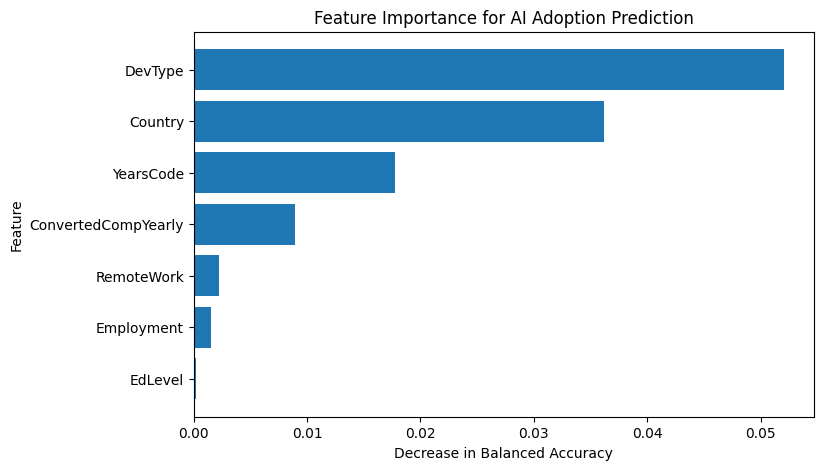

In [92]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Decrease in Balanced Accuracy')
plt.ylabel('Feature')
plt.title('Feature Importance for AI Adoption Prediction')

plt.gca().invert_yaxis()

plt.show()

In [93]:
logistic_model.named_steps['classifier'].classes_

array(['AI User', 'Non-AI User'], dtype=object)

In [94]:
feature_names = logistic_model.named_steps[
    'preprocessor'
].get_feature_names_out()

coefficients = logistic_model.named_steps[
    'classifier'
].coef_[0]

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coefficient_df.head()

,Feature,Coefficient
0,num__YearsCode,0.268032
1,num__ConvertedCompYearly,-0.049539
2,num__missingindicator_YearsCode,0.008711
3,num__missingindicator_ConvertedCompYearly,0.134947
4,cat__DevType_AI/ML engineer,-1.129067


In [95]:
coefficient_df.sort_values(
    'Coefficient',
    ascending=False
).head(15)

,Feature,Coefficient
128,cat__Country_Isle of Man,1.861456
214,cat__Country_Tunisia,0.982065
220,cat__Country_United Kingdom of Great Britain a...,0.981942
184,cat__Country_Republic of Moldova,0.930324
221,cat__Country_United Republic of Tanzania,0.872616
108,cat__Country_France,0.867624
168,cat__Country_Nomadic,0.864025
134,cat__Country_Kazakhstan,0.863036
13,cat__DevType_Database administrator or engineer,0.812092
157,cat__Country_Mongolia,0.798914


In [96]:
coefficient_df.sort_values(
    'Coefficient'
).head(15)

,Feature,Coefficient
185,cat__Country_Republic of North Macedonia,-1.376582
100,cat__Country_Dominican Republic,-1.358424
67,cat__Country_Azerbaijan,-1.158357
4,cat__DevType_AI/ML engineer,-1.129067
224,cat__Country_Uzbekistan,-1.018685
15,"cat__DevType_Developer, AI apps or physical AI",-0.923115
188,cat__Country_Rwanda,-0.920073
26,"cat__DevType_Founder, technology or otherwise",-0.911914
151,cat__Country_Malta,-0.909671
153,cat__Country_Mauritius,-0.905460


In [97]:
devtype_coefficients = coefficient_df[
    coefficient_df['Feature'].str.contains('DevType')
].copy()

devtype_coefficients = devtype_coefficients.sort_values(
    'Coefficient'
)

devtype_coefficients

,Feature,Coefficient
4,cat__DevType_AI/ML engineer,-1.129067
15,"cat__DevType_Developer, AI apps or physical AI",-0.923115
26,"cat__DevType_Founder, technology or otherwise",-0.911914
31,"cat__DevType_Senior executive (C-suite, VP, etc.)",-0.836106
24,cat__DevType_Engineering manager,-0.526611
20,"cat__DevType_Developer, front-end",-0.459469
7,"cat__DevType_Architect, software or solutions",-0.440408
23,"cat__DevType_Developer, mobile",-0.389260
10,cat__DevType_Data engineer,-0.306135
21,"cat__DevType_Developer, full-stack",-0.299915


In [98]:
model_df['DevType'].value_counts()

DevType
Developer, full-stack                            9554
Developer, back-end                              4936
Student                                          2265
Architect, software or solutions                 2152
Developer, desktop or enterprise applications    1554
Developer, front-end                             1484
Other (please specify):                          1379
Developer, mobile                                1045
Developer, embedded applications or devices      1016
Academic researcher                               872
DevOps engineer or professional                   846
Engineering manager                               842
Data engineer                                     595
AI/ML engineer                                    484
Data scientist                                    449
Senior executive (C-suite, VP, etc.)              427
Retired                                           373
System administrator                              364
Developer, game or g

In [99]:
devtype_adoption = (
    model_df.groupby('DevType', observed=True)['AIAdoption']
    .agg(
        Total='count',
        AI_Users=lambda x: (x == 'AI User').sum()
    )
)

devtype_adoption['AI_Adoption_Rate'] = (
    devtype_adoption['AI_Users'] /
    devtype_adoption['Total'] * 100
)

devtype_adoption = devtype_adoption.sort_values(
    'AI_Adoption_Rate',
    ascending=False
)

devtype_adoption.round(1)

,Total,AI_Users,AI_Adoption_Rate
DevType,,,
"Developer, AI apps or physical AI",163,151,92.6
AI/ML engineer,484,445,91.9
"Senior executive (C-suite, VP, etc.)",427,372,87.1
"Founder, technology or otherwise",338,294,87.0
"Developer, front-end",1484,1289,86.9
"Developer, mobile",1045,892,85.4
Engineering manager,842,712,84.6
Data engineer,595,494,83.0
Product manager,154,127,82.5


In [100]:
devtype_adoption_filtered = devtype_adoption[
    devtype_adoption['Total'] >= 200
]

devtype_adoption_filtered.round(1)

,Total,AI_Users,AI_Adoption_Rate
DevType,,,
AI/ML engineer,484,445,91.9
"Senior executive (C-suite, VP, etc.)",427,372,87.1
"Founder, technology or otherwise",338,294,87.0
"Developer, front-end",1484,1289,86.9
"Developer, mobile",1045,892,85.4
Engineering manager,842,712,84.6
Data engineer,595,494,83.0
"Developer, full-stack",9554,7877,82.4
Data scientist,449,370,82.4


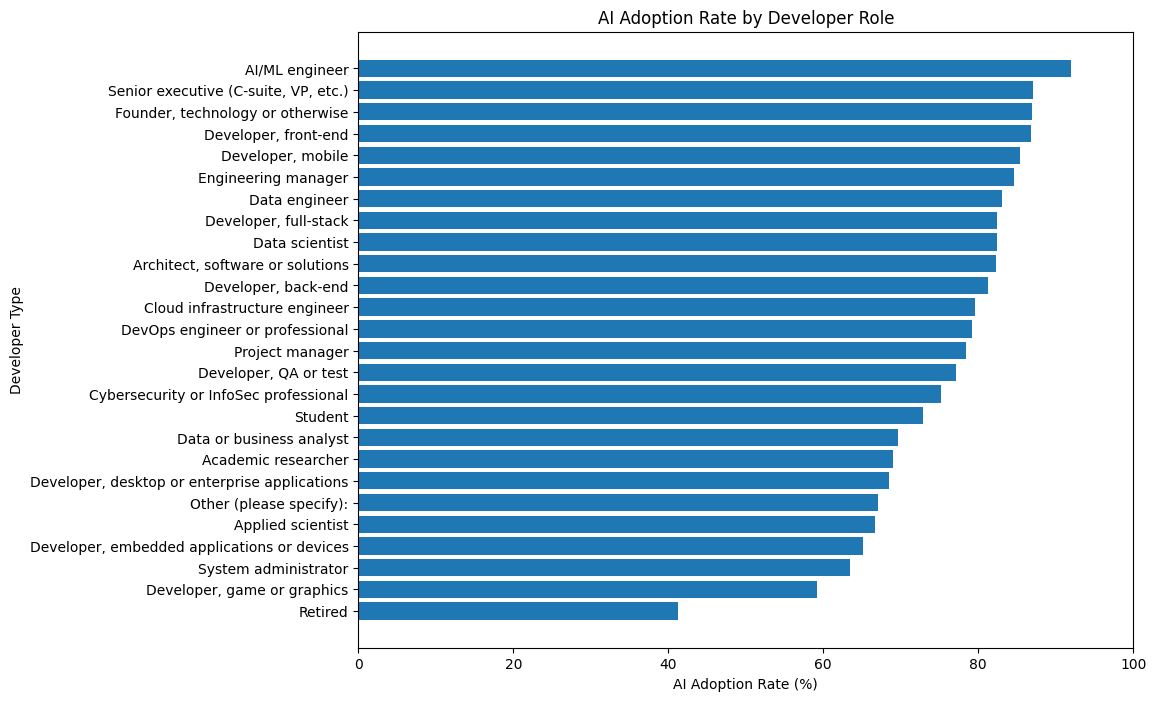

In [101]:
plt.figure(figsize=(10, 8))

plot_data = devtype_adoption_filtered.sort_values(
    'AI_Adoption_Rate',
    ascending=True
)

plt.barh(
    plot_data.index,
    plot_data['AI_Adoption_Rate']
)

plt.xlabel('AI Adoption Rate (%)')
plt.ylabel('Developer Type')
plt.title('AI Adoption Rate by Developer Role')

plt.xlim(0, 100)

plt.show()

### Developer Role and AI Adoption

Developer role was the most important predictor of AI adoption in the balanced logistic regression model. Among roles with at least 200 respondents, AI/ML engineers had the highest AI adoption rate at 91.9%. Senior executives, technology founders, front-end developers, mobile developers, and engineering managers also had adoption rates above 84%.

Lower adoption rates were observed among system administrators (63.5%), game or graphics developers (59.1%), and retired respondents (41.3%).

These results suggest that AI adoption varies considerably across professional roles. However, these differences represent associations within the survey data and should not be interpreted as evidence that a particular developer role causes higher or lower AI adoption.

### Training and Evaluation Summary

A logistic regression model was trained to predict whether a respondent was an AI user based on coding experience, developer role, compensation, education level, employment status, remote-work status, and country.

Because 78.5% of respondents were AI users, a majority-class baseline achieved 78.5% accuracy without actually distinguishing between AI users and non-AI users. A regular logistic regression model achieved 78.7% accuracy but identified only 7% of non-AI users.

To address this class imbalance, a balanced logistic regression model was used. The balanced model achieved 64.2% overall accuracy, 63.5% balanced accuracy, and an ROC-AUC of 0.689. It correctly identified approximately 65% of AI users and 62% of non-AI users.

Permutation importance showed that developer role was the most important predictor, followed by country and years of coding experience. Salary contributed less predictive information, while remote-work status, employment status, and education level contributed relatively little.

Overall, the model demonstrated modest predictive ability. Professional and demographic characteristics appear to contain some information about AI adoption, but they are not sufficient to predict an individual's AI usage with high accuracy.

###  4.2 AI Usage and Developer Salary

In [102]:
salary_df = df[
    ['AIAdoption', 'ConvertedCompYearly']
].dropna()

salary_df.shape

(23203, 2)

In [103]:
salary_summary = salary_df.groupby(
    'AIAdoption'
)['ConvertedCompYearly'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

salary_summary.round(2)

,count,mean,median,std,min,max
AIAdoption,,,,,,
AI User,18720,100569.50,74771.5,474060.73,1.0,50000000.0
Non-AI User,4483,106024.07,80871.0,391027.88,1.0,18387548.0


In [104]:
salary_df.groupby(
    'AIAdoption'
)['ConvertedCompYearly'].median()

AIAdoption
AI User        74771.5
Non-AI User    80871.0
Name: ConvertedCompYearly, dtype: float64

In [105]:
salary_df.groupby(
    'AIAdoption'
)['ConvertedCompYearly'].quantile(
    [0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
).unstack().round(2)

,0.01,0.25,0.50,0.75,0.95,0.99
AIAdoption,,,,,,
AI User,72.00,36407.0,74771.5,120175.5,234028.3,440693.36
Non-AI User,104.46,47472.5,80871.0,123993.0,225000.0,408561.82


In [106]:
salary_df['ConvertedCompYearly'].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).round(2)

count       23203.00
mean       101623.37
std        459187.06
min             1.00
1%             75.00
5%           3000.00
25%         39323.00
50%         75410.00
75%        121000.00
95%        232029.00
99%        427254.00
max      50000000.00
Name: ConvertedCompYearly, dtype: float64

In [107]:
lower_bound = salary_df['ConvertedCompYearly'].quantile(0.01)
upper_bound = salary_df['ConvertedCompYearly'].quantile(0.99)

salary_plot_df = salary_df[
    salary_df['ConvertedCompYearly'].between(
        lower_bound,
        upper_bound
    )
]

<Figure size 800x500 with 0 Axes>

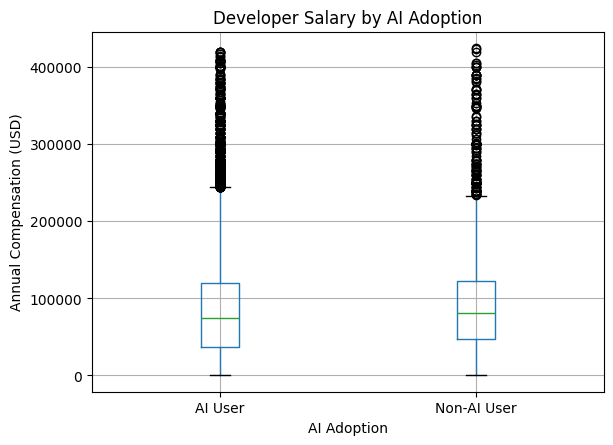

In [108]:
plt.figure(figsize=(8, 5))

salary_plot_df.boxplot(
    column='ConvertedCompYearly',
    by='AIAdoption'
)

plt.title('Developer Salary by AI Adoption')
plt.suptitle('')
plt.xlabel('AI Adoption')
plt.ylabel('Annual Compensation (USD)')
plt.show()

In [109]:
from scipy.stats import mannwhitneyu

ai_salary = salary_df[
    salary_df['AIAdoption'] == 'AI User'
]['ConvertedCompYearly']

non_ai_salary = salary_df[
    salary_df['AIAdoption'] == 'Non-AI User'
]['ConvertedCompYearly']

u_stat, p_value = mannwhitneyu(
    ai_salary,
    non_ai_salary,
    alternative='two-sided'
)

print("U statistic:", u_stat)
print("p-value:", p_value)

U statistic: 39428827.0
p-value: 3.2654291429089063e-10


In [110]:
n1 = len(ai_salary)
n2 = len(non_ai_salary)

rank_biserial = (2 * u_stat) / (n1 * n2) - 1

print(
    "Rank-biserial correlation:",
    round(rank_biserial, 3)
)

Rank-biserial correlation: -0.06


### AI Usage and Developer Salary

The median annual compensation for AI users was approximately $74,772, compared with approximately $80,871 for non-AI users, a difference of about $6,100.

Because the salary distribution was highly skewed and contained extreme values, the Mann–Whitney U test was used instead of relying only on differences in mean salary. The test found a statistically significant difference between the salary distributions of AI users and non-AI users (p < .001).

However, the rank-biserial correlation was only -0.06, indicating a very small effect size. This suggests that although non-AI users earned slightly more in this sample, AI usage was only weakly associated with salary.

The salary boxplot was limited to the 1st through 99th percentile for visualization so that extreme salary values would not dominate the graph. The statistical test itself used the full salary dataset.

###  4.3 AI Usage and Career Outlook

In [111]:
df['AIThreat'].value_counts(dropna=False)

AIThreat
No              22958
NaN             13113
I'm not sure     7700
Yes              5420
Name: count, dtype: int64

In [112]:
threat_table = pd.crosstab(
    df['AIAdoption'],
    df['AIThreat'],
    normalize='index'
) * 100

threat_table.round(1)

AIThreat,I'm not sure,No,Yes
AIAdoption,,,
AI User,21.9,62.9,15.2
Non-AI User,18.9,69.9,11.2


In [113]:
threat_counts = pd.crosstab(
    df['AIAdoption'],
    df['AIThreat']
)

threat_counts

AIThreat,I'm not sure,No,Yes
AIAdoption,,,
AI User,5731,16482,3973
Non-AI User,1312,4853,775


In [114]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(threat_counts)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 125.89353414698436
p-value: 4.597972890272402e-28
Degrees of freedom: 2


In [115]:
import numpy as np

n = threat_counts.to_numpy().sum()
min_dim = min(threat_counts.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * min_dim)
)

print("Cramer's V:", round(cramers_v, 3))

Cramer's V: 0.062


### AI Usage and Career Outlook

AI users were somewhat more likely to view AI as a threat to their jobs than non-AI users. Approximately 15.2% of AI users said that AI threatens their current job, compared with 11.2% of non-AI users.

A chi-square test found a statistically significant relationship between AI adoption and perceptions of AI as a job threat, χ²(2) = 125.89, p < .001. However, Cramér's V was only 0.062, indicating that the association was very weak.

These results suggest that using AI does not necessarily reduce concerns about its impact on employment. In this sample, AI users were actually slightly more likely to report feeling threatened by AI, although the difference between the groups was small.

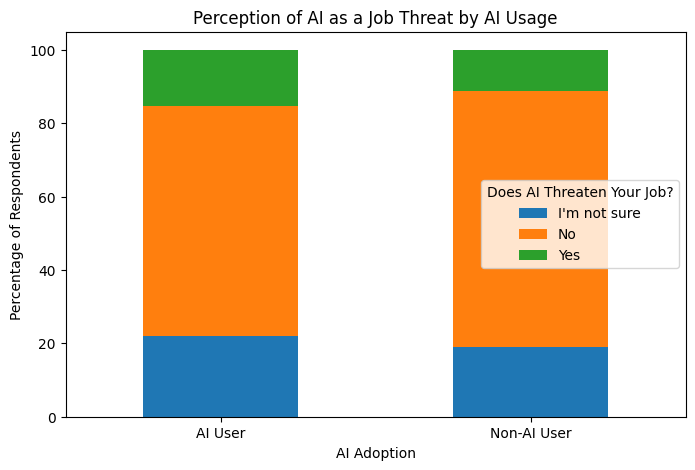

In [116]:
threat_table.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Perception of AI as a Job Threat by AI Usage')
plt.xlabel('AI Adoption')
plt.ylabel('Percentage of Respondents')
plt.xticks(rotation=0)
plt.legend(title='Does AI Threaten Your Job?')
plt.show()

## 5. Modeling and Evaluation
   Predict AI adoption
   
   The goal of the modeling stage is to determine whether developer characteristics can be used to predict current AI adoption.

Because the target variable, `AIAdoption`, contains two categories (`AI User` and `Non-AI User`), this is a binary classification problem.

In [47]:
# Select features for predicting AI adoption
model_df = df[
    [
        'AIAdoption',
        'WorkExp',
        'ConvertedCompYearly',
        'RemoteWork',
        'EdLevel'
    ]
].copy()

In [48]:
# Check missing values in the modeling variables
model_df.isna().sum()

AIAdoption             15471
WorkExp                 6352
ConvertedCompYearly    25244
RemoteWork             15411
EdLevel                 1042
dtype: int64

In [49]:
# Remove rows where the target variable is missing
model_df = model_df.dropna(subset=['AIAdoption'])

In [50]:
model_df['AIAdoption'].value_counts(normalize=True) * 100

AIAdoption
AI User        78.496441
Non-AI User    21.503559
Name: proportion, dtype: float64

In [51]:
# Remove rows missing the selected modeling features
model_df = model_df.dropna(
    subset=[
        'WorkExp',
        'ConvertedCompYearly',
        'RemoteWork',
        'EdLevel'
    ]
)

In [52]:
# Check the number of usable rows after removing missing feature values
model_df.shape

(20168, 5)

In [53]:
# Convert AI adoption labels into binary values for classification
model_df['AIAdoptionBinary'] = model_df['AIAdoption'].map({
    'Non-AI User': 0,
    'AI User': 1
})

In [54]:
# Convert categorical variables into numeric dummy variables
model_df = pd.get_dummies(
    model_df,
    columns=['RemoteWork', 'EdLevel'],
    drop_first=True
)

In [55]:
# Separate predictor variables from the target variable
X = model_df.drop(
    columns=['AIAdoption', 'AIAdoptionBinary']
)

y = model_df['AIAdoptionBinary']

In [56]:
X.head()

,WorkExp,ConvertedCompYearly,"RemoteWork_Hybrid (some remote, leans heavy to in-person)",RemoteWork_In-person,RemoteWork_Remote,"RemoteWork_Your choice (very flexible, you can come in when you want or just as needed)","EdLevel_Bachelor’s degree (B.A., B.S., B.Eng., etc.)","EdLevel_Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",EdLevel_Other (please specify):,EdLevel_Primary/elementary school,"EdLevel_Professional degree (JD, MD, Ph.D, Ed.D, etc.)","EdLevel_Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",EdLevel_Some college/university study without earning a degree
0,8.0,61256.0,False,False,True,False,False,True,False,False,False,False,False
1,2.0,104413.0,False,False,False,False,False,False,False,False,False,False,False
3,4.0,36197.0,False,False,True,False,True,False,False,False,False,False,False
7,22.0,72000.0,False,False,True,False,False,False,False,False,True,False,False
8,9.0,70000.0,False,False,True,False,True,False,False,False,False,False,False


In [ ]:
X.shape

6. Prediction Scenario


7. Conclusions